# Foundations of Data Science
## Tutorial 1 — Python & Probability Simulation

Welcome! This is the first tutorial session. We'll get comfortable with Jupyter, NumPy, and matplotlib, and then use Python to *simulate* random variables — a skill that will come back again and again in this course.

**Today's plan:**
1. Jupyter & Python refresher (lists, dicts, functions)
2. NumPy for numerical work
3. Plotting with matplotlib
4. Simulating random variables
5. Monte Carlo estimation of expectations
6. Two guided exercises (cheating dice & an algorithmic RV)
7. Visual intuition for Markov's inequality (→ homework)

**How to use this notebook:** `Shift + Enter` runs the current cell. Cells marked *`# your code here`* are for you to fill in. Don't be afraid to break things — you can always re-run from the top.

### A few Jupyter tips

- `?np.mean` opens the docstring for `np.mean`.
- `!ls` runs a shell command from within a cell.
- Variables persist across cells in the order you execute them (not the order they appear!).

In [1]:
# Try it: run this cell with Shift+Enter
print("Hello, Foundations of Data Science!")

Hello, Foundations of Data Science!


## 1. Python basics

A quick tour of Python's built-in data structures. If you already know this, skim and run the cells — you'll need them for later sections.

### Lists and dictionaries

Python **lists** are ordered, mutable sequences. **Dictionaries** are key→value lookup tables. Both can hold mixed types.

In [3]:
dice_rolls = [3, 1, 4, 1, 5, 9, 2, 6]
print("length:", len(dice_rolls))
print("first three:", dice_rolls[:3])
print("last:", dice_rolls[-1])

length: 8
first three: [3, 1, 4]
last: 6


In [4]:
die_probabilities = {1: 1/6, 2: 1/6, 3: 1/6, 4: 1/6, 5: 1/6, 6: 1/6}
print(die_probabilities[3])
print("sum of probabilities:", sum(die_probabilities.values()))

0.16666666666666666
sum of probabilities: 0.9999999999999999


### Functions & list comprehensions

Write small functions — they make your code reusable and easy to test.

In [5]:
def is_even(n):
    return n % 2 == 0

# List comprehension: "give me is_even(r) for every r in dice_rolls"
even_flags = [is_even(r) for r in dice_rolls]
print(even_flags)

# How many even rolls?
print("count of even rolls:", sum(even_flags))

[False, False, True, False, False, False, True, True]
count of even rolls: 3


### Exercise 1.0 — warm-up

Write a function `mean(values)` that takes a list of numbers and returns their average. Test it on `dice_rolls` above. You are **not allowed** to use `sum(...)/len(...)` — write the loop yourself.

In [6]:
# your code here
def mean(values):
    sum = 0
    for i in range(len(values)):
        sum += values[i]

    return sum/len(values)

print(f"Mean(Dice Rolls) = {mean(dice_rolls)}")

Mean(Dice Rolls) = 3.875


## 2. NumPy

Python lists are flexible but slow for numerical work. **NumPy** gives you C-speed array operations and is the foundation of almost every data science library (pandas, scikit-learn, PyTorch…).

In [7]:

import numpy as np

rolls = np.array([3, 1, 4, 1, 5, 9, 2, 6])
print("array:", rolls)
print("mean:", rolls.mean())
print("std:", rolls.std())
print("sum:", rolls.sum())

array: [3 1 4 1 5 9 2 6]
mean: 3.875
std: 2.5708704751503917
sum: 31


### Vectorized operations

Operations on arrays happen element-wise — no Python loops needed. This is both more concise and much faster.

In [8]:
x = np.arange(10)          # 0, 1, 2, ..., 9
print("x         :", x)
print("x * 2     :", x * 2)
print("x ** 2    :", x ** 2)
print("x > 5     :", x > 5)
print("x[x > 5]  :", x[x > 5])   # boolean indexing

x         : [0 1 2 3 4 5 6 7 8 9]
x * 2     : [ 0  2  4  6  8 10 12 14 16 18]
x ** 2    : [ 0  1  4  9 16 25 36 49 64 81]
x > 5     : [False False False False False False  True  True  True  True]
x[x > 5]  : [6 7 8 9]


### Exercise 1.1 — vectorize!

Rewrite your `mean(values)` function from Exercise 1.0 using NumPy, so that it works on a NumPy array without a Python `for` loop. Hint: you still shouldn't use `.mean()` directly — use `.sum()` and `len()`.

In [9]:
# your code here
def mean_new(values):
    return np.sum(values)/len(values)

mean_new(dice_rolls)

np.float64(3.875)

### Random numbers

For reproducible experiments, always create a `Generator` with a fixed seed. Then sample from it:

In [10]:
rng = np.random.default_rng(42)

uniform_samples = rng.uniform(0, 1, size=5)
print("uniform [0,1]:", uniform_samples)

normal_samples  = rng.standard_normal(size=5)
print("N(0,1)       :", normal_samples)

die_rolls = rng.integers(1, 7, size=10)   # 1..6 inclusive
print("die rolls    :", die_rolls)

uniform [0,1]: [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]
N(0,1)       : [-1.30217951  0.1278404  -0.31624259 -0.01680116 -0.85304393]
die rolls    : [4 3 2 6 5 4 3 5 4 3]


## 3. Plotting

We'll use `matplotlib` throughout the course. Two workhorses: `plt.plot` for line/scatter plots, and `plt.hist` for distributions.

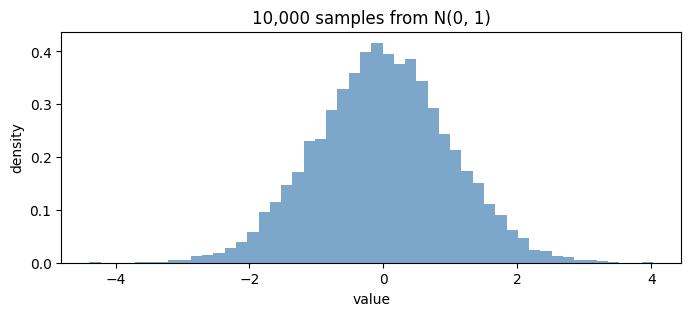

In [11]:
import matplotlib.pyplot as plt

samples = rng.standard_normal(size=10000)

plt.figure(figsize=(8, 3))
plt.hist(samples, bins=50, density=True, alpha=0.7, color="steelblue")
plt.xlabel("value")
plt.ylabel("density")
plt.title("10,000 samples from N(0, 1)")
plt.show()

## 4. Simulating random variables

A random variable is just a function: given some random input, it spits out a number. In Python we write it as a function that calls `rng.something()` and returns a value.

**Example.** The fair die $D \leftarrow \{1,2,3,4,5,6\}$ uniformly:

In [12]:
def roll_die(rng):
    return rng.integers(1, 7)          # single roll

# Simulate 10,000 rolls
N = 10_000
rolls = np.array([roll_die(rng) for _ in range(N)])
print("empirical mean :", rolls.mean())
print("theoretical E(D) = (1+2+3+4+5+6)/6 =", (1+2+3+4+5+6)/6)

empirical mean : 3.5313
theoretical E(D) = (1+2+3+4+5+6)/6 = 3.5


### The Law of Large Numbers, visually

As we average more samples, the empirical mean converges to the true expectation. Let's watch it happen.

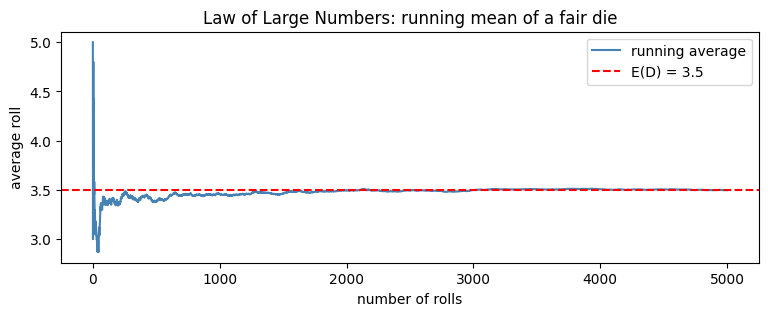

In [13]:
rolls = rng.integers(1, 7, size=5000)
running_mean = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)

plt.figure(figsize=(9, 3))
plt.plot(running_mean, color="steelblue", label="running average")
plt.axhline(3.5, color="red", linestyle="--", label="E(D) = 3.5")
plt.xlabel("number of rolls")
plt.ylabel("average roll")
plt.title("Law of Large Numbers: running mean of a fair die")
plt.legend()
plt.show()

### Exercise 1.2 — estimate a probability by simulation

Use simulation to estimate $\Pr[D \geq 5]$ for a fair die $D$. Do it two ways and compare:

1. Draw $N = 100{,}000$ die rolls and compute the fraction $\geq 5$.
2. Compare to the exact answer $2/6 = 1/3$.

**Hint:** `(rolls >= 5).mean()` gives you the fraction in one line.

In [17]:
# your code here
# Single die roll
def single_roll(rng):
    # Return a single random number btwn 1 - 6
    return rng.integers(1, 7)

N = 100_000

# Simulate 100,000 die rolls
rolls = np.array([single_roll(rng) for _ in range(N)])

print(f"Empirical Mean: {(rolls).mean()}")
print(f"Empirical Mean: {(rolls >= 5).mean()}")
print(f"Theoretical Mean: {(2/6)}")

Empirical Mean: 3.49888
Empirical Mean: 0.33443
Theoretical Mean: 0.3333333333333333


## 5. The cheating dice player

A player rolls a fair die $D \leftarrow \{1, \dots, 6\}$ and tosses a fair coin $C \leftarrow \{0, 1\}$. The player is a **cheater**: if the coin comes up *heads* ($C = 1$), they secretly change the die's outcome to $6$. Otherwise they report $D$ honestly. Let $F$ be the *reported* outcome.

### Part (a): describe F as a function of C and D

Think before coding:
- If $C = 0$ (tails, honest), what is $F$?
- If $C = 1$ (heads, cheats), what is $F$?

Answer: $\; F = \begin{cases} D & \text{if } C = 0 \\ 6 & \text{if } C = 1 \end{cases}$

Let's implement it.

In [ ]:
def cheater_trial(rng):
    C = rng.integers(0, 2)       # 0 or 1
    D = rng.integers(1, 7)       # 1..6
    F = 6 if C == 1 else D
    return C, D, F

# Run a few trials to see what happens
for _ in range(5):
    print(cheater_trial(rng))

(np.int64(1), np.int64(6), 6)
(np.int64(1), np.int64(3), 6)
(np.int64(1), np.int64(3), 6)
(np.int64(1), np.int64(2), 6)
(np.int64(0), np.int64(5), np.int64(5))


### Part (b): joint distribution of (C, F)

The pair $(C, F)$ is a random variable with outputs in $\{0, 1\} \times \{1, 2, 3, 4, 5, 6\}$.  We want the $2 \times 6$ table of probabilities $\Pr[C = c, F = f]$.

**Your turn:** Simulate $N = 100{,}000$ trials, then count how often each $(c, f)$ pair occurs and divide by $N$. Store the result in a $2 \times 6$ array `joint_empirical[c, f-1]`.

In [18]:
# your code here
# Hint: vectorize it — don't loop 100,000 times in Python.
N = 100_000
Cs = rng.integers(0, 2, size=N)
Ds = rng.integers(1, 7, size=N)
Fs = np.where(Cs == 1, 6, Ds)

#   Then use np.histogram2d or a small loop over (c, f).
joint_counts, _, _, = np.histogram2d(Cs, Fs, bins=[2, 6], range=[[0,2], [1,7]])
joint_empirical=joint_counts/N

print(joint_empirical)

[[0.08339 0.08394 0.0837  0.08319 0.08394 0.0815 ]
 [0.      0.      0.      0.      0.      0.50034]]


**Theoretical answer** (for comparison):

| $C \backslash F$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| 0 | $1/12$ | $1/12$ | $1/12$ | $1/12$ | $1/12$ | $1/12$ |
| 1 | 0 | 0 | 0 | 0 | 0 | $1/2$ |

Rows sum to $1/2$ (prob. of $C = 0$ or $C = 1$), and the whole table sums to 1.

In [ ]:
joint_theoretical = np.zeros((2, 6))
joint_theoretical[0, :] = 1/12
joint_theoretical[1, 5] = 1/2
print(joint_theoretical)
print("total:", joint_theoretical.sum())

### Part (c): are C and F independent?

Two random variables are independent iff $\Pr[C = c, F = f] = \Pr[C = c] \cdot \Pr[F = f]$ for all $c, f$.

**Your turn:**
1. From your empirical joint table, compute the marginals $\Pr[C = c]$ and $\Pr[F = f]$ (sum rows / sum columns).
2. Build the $2 \times 6$ product table $\Pr[C = c] \cdot \Pr[F = f]$.
3. Compare it cell-by-cell to the joint table. Are they equal?

In [ ]:
# your code here
# Hint:
  marginal_C = joint_empirical.sum(axis=1)   # shape (2,)
  marginal_F = joint_empirical.sum(axis=0)   # shape (6,)
  product    = np.outer(marginal_C, marginal_F)
  # Compare product to joint_empirical

## 6. An algorithmic random variable

(This is what used to be Exercise 1.3 on the homework sheet.)

Consider this algorithm:

```
1. Toss a coin C ← {0, 1}.
2. Choose X ← [0, 1] uniformly.
3. Roll a die D ← {1, ..., 6}.
4. If C = 0, let Z ← D + X.
5. Else,     let Z ← D - X.
6. Return Z.
```

The output $Z$ is a random variable. We want to compute $\mathbb{E}(Z)$, $\mathbb{E}(Z^2)$ and $\mathrm{var}(Z)$.

### Step 1: implement the algorithm

Write a vectorized simulator that returns $N$ independent samples of $Z$.

In [19]:
def sample_Z(N, rng):
    C = rng.integers(0, 2, size=N)           # 0 or 1
    X = rng.uniform(0, 1, size=N)            # [0, 1]
    D = rng.integers(1, 7, size=N)           # 1..6
    Z = np.where(C == 0, D + X, D - X)
    return Z

Z_samples = sample_Z(100_000, rng)
print("first 5 samples:", Z_samples[:5])
print("empirical mean :", Z_samples.mean())
print("empirical var  :", Z_samples.var())

first 5 samples: [4.09858762 4.91575341 5.19929836 4.18624212 3.54136667]
empirical mean : 3.4896254111270526
empirical var  : 3.2579411112252536


### Step 2: visualize the distribution of Z

Before computing moments, let's *look* at $Z$. What do you expect?

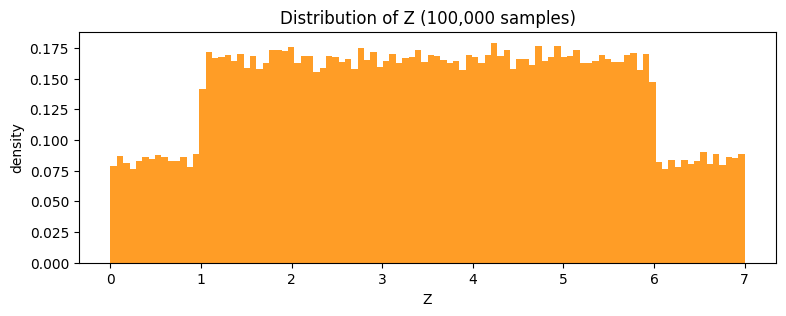

In [ ]:
plt.figure(figsize=(9, 3))
plt.hist(Z_samples, bins=100, density=True, color="darkorange", alpha=0.85)
plt.xlabel("Z")
plt.ylabel("density")
plt.title("Distribution of Z (100,000 samples)")
plt.show()

### Step 3: estimate E(Z), E(Z²), var(Z)

**Your turn:** fill in the cell below. Then compare to the theoretical answers derived with pen and paper — see if your simulation agrees.

Hints for the theory:
- By symmetry, $\mathbb{E}(Z) = \mathbb{E}(D) = 7/2$. Why?
- For $\mathbb{E}(Z^2)$, expand: $Z^2 = D^2 \pm 2DX + X^2$. The cross-term vanishes in expectation. Why?
- $\mathbb{E}(D^2) = \tfrac{1}{6}\sum_{k=1}^{6} k^2 = 91/6$, and $\mathbb{E}(X^2) = 1/3$.

In [21]:
# your code here: estimate E(Z), E(Z^2), var(Z) from Z_samples
# Then print the theoretical values and compare.
E_Z = np.mean(Z_samples)
E_Z2 = np.mean(Z_samples**2)
varZ = np.var(Z_samples)

print(f"Estimated E[Z]: {E_Z}")
print(f"Estimated E[Z^2]: {E_Z2}")
print(f"Estimated Var(Z): {varZ}")

Estimated E[Z]: 3.4896254111270526
Estimated E[Z^2]: 15.435426621208906
Estimated Var(Z): 3.2579411112252536


**Theoretical answers** (check against your simulation):

$$\mathbb{E}(Z) = \frac{7}{2} = 3.5$$

$$\mathbb{E}(Z^2) = \mathbb{E}(D^2) + \mathbb{E}(X^2) = \frac{91}{6} + \frac{1}{3} \approx 15.500$$

$$\mathrm{var}(Z) = \mathbb{E}(Z^2) - \mathbb{E}(Z)^2 = \frac{91}{6} + \frac{1}{3} - \frac{49}{4} \approx 3.250$$

## 7. Markov's inequality — a teaser for the homework

For a non-negative random variable $X$ and $a > 0$:
$$ \Pr[X \geq a] \leq \frac{\mathbb{E}(X)}{a} $$

The right-hand side is an *upper bound* — sometimes tight, sometimes very loose. Let's visualize both sides for $X \sim \mathcal{U}[0, 1]$, so $\mathbb{E}(X) = 1/2$.

On the homework (Exercise 1.4) you'll do this for the Gaussian and a fair die as well.

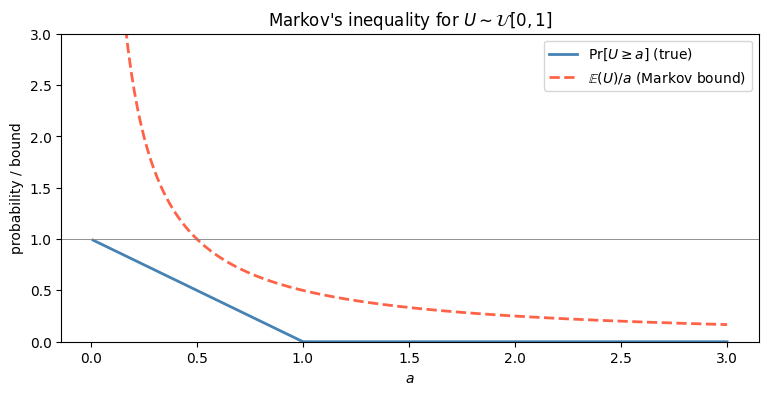

In [ ]:
a_values = np.linspace(0.01, 3, 200)
true_prob  = np.clip(1 - a_values, 0, 1)     # P(U >= a) for U ~ U[0,1]
markov_bound = 0.5 / a_values                # E(U)/a

plt.figure(figsize=(9, 4))
plt.plot(a_values, true_prob,     label=r"$\Pr[U \geq a]$ (true)",   color="steelblue", lw=2)
plt.plot(a_values, markov_bound,  label=r"$\mathbb{E}(U)/a$ (Markov bound)", color="tomato", lw=2, linestyle="--")
plt.axhline(1, color="gray", lw=0.6)
plt.ylim(0, 3)
plt.xlabel("$a$")
plt.ylabel("probability / bound")
plt.title("Markov's inequality for $U \\sim \\mathcal{U}[0, 1]$")
plt.legend()
plt.show()

**Observe:**
- For small $a$, the Markov bound explodes above 1 — useless (a probability is always ≤ 1).
- For $a$ close to $\mathbb{E}(U) = 0.5$, the bound is already quite loose.
- Markov knows *nothing* about the distribution shape, only its mean. That's why it's loose.

On the homework you'll repeat this for $\mathcal{N}(0, 1)$ (where Markov doesn't apply directly — why?) and for a fair die, and you'll add Chebyshev's inequality, which uses the variance and is usually tighter.

## Wrap up

Today you:

- got fluent with Jupyter, NumPy, and matplotlib
- saw the Law of Large Numbers in action
- simulated a joint distribution and checked independence empirically
- estimated moments of a random variable defined by an algorithm
- got a preview of Markov's inequality

**For the homework (Sheet 1):** solve Exercises 1.1 (max of two dice) and 1.2 (Markov & Chebyshev).  The simulation techniques from today are useful for sanity-checking your analytic answers — always a good habit.